<a href="https://colab.research.google.com/github/athfizh/PemMes26_05_Hafizh/blob/main/JS09/JS09-TugasLab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

# **Hierarchical Clustering - Tugas Lab 2**

---

> Tugas Lab 2 meminta klasterisasi HDBSCAN pada dataset nyata dari `sklearn.datasets`, lalu melaporkan jumlah klaster, banyaknya noise, visualisasi (dengan PCA karena datanya 4 dimensi), dan analisis kesesuaiannya dengan label asli. Di sini dipakai **iris dataset** karena punya 3 spesies asli sebagai pembanding.

---

# **Langkah 0 - Persiapan Lingkungan**

---

In [1]:
# Instalasi library hdbscan (tidak tersedia default di sklearn)
!pip install hdbscan

import pandas as pd
import matplotlib.pyplot as plt

import hdbscan
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

> `!pip install hdbscan` wajib karena library ini bukan bawaan scikit-learn. `load_iris` memuat dataset, `PCA` mereduksi 4 fitur jadi 2 dimensi untuk plot, sedangkan `adjusted_rand_score` dan `normalized_mutual_info_score` dipakai untuk mengukur kesesuaian hasil klaster dengan label spesies asli.

---

# **Langkah 1 - Klasterisasi Iris dengan HDBSCAN**

---

In [2]:
iris = load_iris()
X_iris = iris.data
y_true = iris.target

hdb = hdbscan.HDBSCAN(min_cluster_size=5, min_samples=5)
label_hdb = hdb.fit_predict(X_iris)

print('Jumlah klaster:', len(set(label_hdb)) - (1 if -1 in label_hdb else 0))
print('Jumlah noise  :', list(label_hdb).count(-1))
print('Anggota tiap label:')
print(pd.Series(label_hdb).value_counts().sort_index())

Jumlah klaster: 2
Jumlah noise  : 0
Anggota tiap label:
0     50
1    100
Name: count, dtype: int64


> Dataset iris berisi 150 bunga dengan 4 fitur (panjang dan lebar sepal serta petal) dan 3 spesies asli. `min_cluster_size=5` berarti kelompok minimal 5 titik dianggap klaster, `min_samples=5` menentukan seberapa padat sebuah titik dianggap inti. Hasilnya **2 klaster dan 0 noise**: satu klaster berisi 50 titik dan satu lagi 100 titik. `len(set(...))` menghitung jumlah label unik, lalu dikurangi 1 kalau ada label noise (-1).

---

# **Langkah 2 - Visualisasi dengan PCA**

---

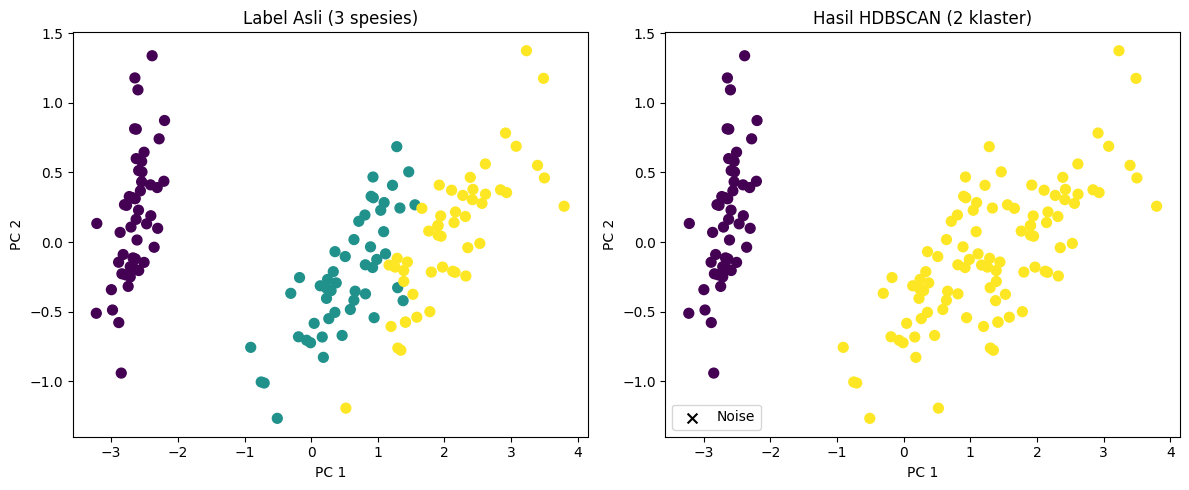

In [3]:
# Reduksi dimensi 4 fitur menjadi 2 komponen
pca = PCA(n_components=2, random_state=0)
X_pca = pca.fit_transform(X_iris)

noise = label_hdb == -1

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Panel kiri: label asli
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y_true, cmap='viridis', s=50)
axes[0].set_title('Label Asli (3 spesies)')
axes[0].set_xlabel('PC 1')
axes[0].set_ylabel('PC 2')

# Panel kanan: hasil HDBSCAN
axes[1].scatter(X_pca[~noise, 0], X_pca[~noise, 1], c=label_hdb[~noise], cmap='viridis', s=50)
axes[1].scatter(X_pca[noise, 0], X_pca[noise, 1], c='black', marker='x', s=50, label='Noise')
axes[1].set_title('Hasil HDBSCAN (2 klaster)')
axes[1].set_xlabel('PC 1')
axes[1].set_ylabel('PC 2')
axes[1].legend()

plt.tight_layout()
plt.show()

> PCA memampatkan 4 fitur jadi 2 komponen utama supaya data bisa digambar di bidang dua dimensi; dua komponen ini menyimpan sekitar 97,8% informasi data (PC 1 saja 92,5%). Panel kiri adalah label asli, panel kanan hasil HDBSCAN dengan noise ditandai `x` hitam (di sini tidak ada). Terlihat setosa terpisah jelas di kiri, sedangkan versicolor dan virginica saling tumpang tindih di kanan. `~noise` membalik boolean supaya titik non-noise yang digambar berwarna.

---

# **Langkah 3 - Perbandingan dengan Label Asli**

---

In [4]:
print(pd.crosstab(y_true, label_hdb))
print(f'Adjusted Rand Index: {adjusted_rand_score(y_true, label_hdb):.4f}')
print(f'Normalized Mutual Information: {normalized_mutual_info_score(y_true, label_hdb):.4f}')

col_0   0   1
row_0        
0      50   0
1       0  50
2       0  50
Adjusted Rand Index: 0.5681
Normalized Mutual Information: 0.7337


> Crosstab memperlihatkan label 0 berisi 50 setosa semuanya, sedangkan label 1 berisi 50 versicolor ditambah 50 virginica. ARI `0.5681` dan NMI `0.7337` tergolong cukup tinggi, tetapi tidak sempurna karena dua spesies terakhir memang berimpit di ruang fitur. ARI dan NMI bernilai 1 kalau hasil klaster identik dengan label asli.

---

# **Langkah 4 - Uji Stabilitas min_cluster_size**

---

In [5]:
for mcs in [5, 10, 15, 20, 25]:
    h = hdbscan.HDBSCAN(min_cluster_size=mcs).fit(X_iris)
    n_cluster = len(set(h.labels_)) - (1 if -1 in h.labels_ else 0)
    n_noise = int((h.labels_ == -1).sum())
    print(f'min_cluster_size={mcs:2d} | klaster={n_cluster} | noise={n_noise:2d} | ARI={adjusted_rand_score(y_true, h.labels_):.4f}')

min_cluster_size= 5 | klaster=2 | noise= 0 | ARI=0.5681
min_cluster_size=10 | klaster=2 | noise= 0 | ARI=0.5681
min_cluster_size=15 | klaster=2 | noise= 1 | ARI=0.5657
min_cluster_size=20 | klaster=2 | noise= 3 | ARI=0.5621
min_cluster_size=25 | klaster=2 | noise= 5 | ARI=0.5601


> Menaikkan `min_cluster_size` membuat klaster makin ketat. Jumlah klaster tetap 2, tetapi noise mulai muncul saat nilainya 15 (1, 3, lalu 5 titik) dan ARI turun tipis dari `0.5681` ke `0.5601`. Artinya hasilnya stabil dan tidak terlalu sensitif terhadap perubahan parameter, karena struktur iris memang hanya punya dua wilayah padat yang benar-benar terpisah.

> **Analisis singkat.** Hasil HDBSCAN belum sepenuhnya sesuai label asli. Setosa berhasil dipisahkan dengan sempurna (50 dari 50 titik), tetapi versicolor dan virginica digabung menjadi satu klaster. Ini wajar karena di ruang fitur keduanya memang beririsan, misalnya panjang petal versicolor 3,0-5,1 cm sedangkan virginica 4,5-6,9 cm, sehingga wilayahnya menyambung dan membentuk satu pulau kepadatan. HDBSCAN mengelompokkan berdasarkan kepadatan titik, bukan berdasarkan spesies, jadi dua kelas yang berdekatan akan dianggap satu klaster. Kalau ketiganya ingin terpisah, perlu fitur tambahan atau algoritma yang jumlah klasternya ditentukan di awal seperti K-Means dengan k = 3.

> Ringkasnya, HDBSCAN pada iris menghasilkan 2 klaster tanpa noise dengan ARI 0.5681 dan NMI 0.7337. Hasilnya hanya cocok sebagian dengan label asli karena dua dari tiga spesies saling tumpang tindih, bukan karena algoritmanya salah.